## Importación de Librerías y Descarga de Datos

In [51]:
# =============================================================================
# CONFIGURACIÓN INICIAL E INGESTA DE MARKET DATA
# =============================================================================
# =============================================================================
# CELDA 1: CONFIGURACIÓN INICIAL E INGESTA DE MARKET DATA
# =============================================================================
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import coint

# Definición de los activos institucionales (ADRs en USD para mayor estabilidad)
TICKER_A = "GGAL"
TICKER_B = "BMA"
START_DATE = "2018-01-01"
END_DATE = "2024-01-01"

print("Descargando series de tiempo históricas...")

# Descarga explícita del DataFrame de mercado completo
df_a = yf.download(TICKER_A, start=START_DATE, end=END_DATE, auto_adjust=True, progress=False)
df_b = yf.download(TICKER_B, start=START_DATE, end=END_DATE, auto_adjust=True, progress=False)

# Extracción segura de la columna 'Close' como Series conservando el índice cronológico
series_a = df_a['Close'].squeeze()
series_b = df_b['Close'].squeeze()

# Consolidación explícita mediante un diccionario con alineación nativa de Pandas
df_pairs = pd.DataFrame({
    TICKER_A: series_a,
    TICKER_B: series_b
}).dropna()

print(f"✅ Estructura de datos lista. Registros totales: {len(df_pairs)} ruedas operativas.")



Descargando series de tiempo históricas...
✅ Estructura de datos lista. Registros totales: 1509 ruedas operativas.


## El Filtro Quant Estricto (Prueba de Cointegración de Engle-Granger)

In [52]:
# =============================================================================
#  ANÁLISIS ESTADÍSTICO DE COINTEGRACIÓN
# =============================================================================
print("Ejecutando Test de Cointegración de Engle-Granger...")

# La función coint nos devuelve el estadístico t, el p-valor y los valores críticos
score, p_value, crit_value = coint(df_pairs[TICKER_A], df_pairs[TICKER_B])

print("-" * 50)
print(f"Resultados del Test Estadístico ({TICKER_A} vs {TICKER_B}):")
print(f"- Estadístico de la prueba: {score:.4f}")
print(f"- p-valor obtenido: {p_value:.4f}")
print("-" * 50)

if p_value < 0.05:
    print(f"✅ ¡Éxito Cuantitativo! p-valor ({p_value:.4f}) < 0.05. El par está COINTEGRADO.")
    print("Existe una relación de equilibrio de largo plazo. El spread es estacionario.")
else:
    print(f"❌ Alerta: p-valor ({p_value:.4f}) >= 0.05. No hay evidencia estadística de cointegración.")
    print("El spread podría divergir indefinidamente y no revertir a la media.")


Ejecutando Test de Cointegración de Engle-Granger...
--------------------------------------------------
Resultados del Test Estadístico (GGAL vs BMA):
- Estadístico de la prueba: -3.2613
- p-valor obtenido: 0.0603
--------------------------------------------------
❌ Alerta: p-valor (0.0603) >= 0.05. No hay evidencia estadística de cointegración.
El spread podría divergir indefinidamente y no revertir a la media.


## Cálculo del Spread y Z-Score Dinámico

In [53]:
# =============================================================================
# INGENIERÍA DE FEATURES - CÁLCULO DEL SPREAD Y Z-SCORE
# =============================================================================
# 1. Ajustamos un modelo de regresión lineal para encontrar la proporción exacta (Hedge Ratio)
X_reg = sm.add_constant(df_pairs[TICKER_B])
modelo_reg = sm.OLS(df_pairs[TICKER_A], X_reg).fit()
hedge_ratio = modelo_reg.params[TICKER_B]

# 2. Calculamos el spread matemático real entre ambos activos
df_pairs['Spread'] = df_pairs[TICKER_A] - (hedge_ratio * df_pairs[TICKER_B])

# 3. Calculamos la media y desviación estándar móvil (Rolling) para simular mercado en vivo
window = 30 # Ventana móvil de 30 días para capturar cambios dinámicos
df_pairs['Spread_Mean'] = df_pairs['Spread'].rolling(window=window).mean()
df_pairs['Spread_Std'] = df_pairs['Spread'].rolling(window=window).std()

# 4. Cálculo del Z-Score analítico institucional
df_pairs['Z_Score'] = (df_pairs['Spread'] - df_pairs['Spread_Mean']) / df_pairs['Spread_Std']
df_pairs = df_pairs.dropna()

print(f"Cálculo de Z-Score finalizado. Proporción de cobertura (Hedge Ratio): {hedge_ratio:.4f}")


Cálculo de Z-Score finalizado. Proporción de cobertura (Hedge Ratio): 0.6517


## Visualización del Spread y Z-Score

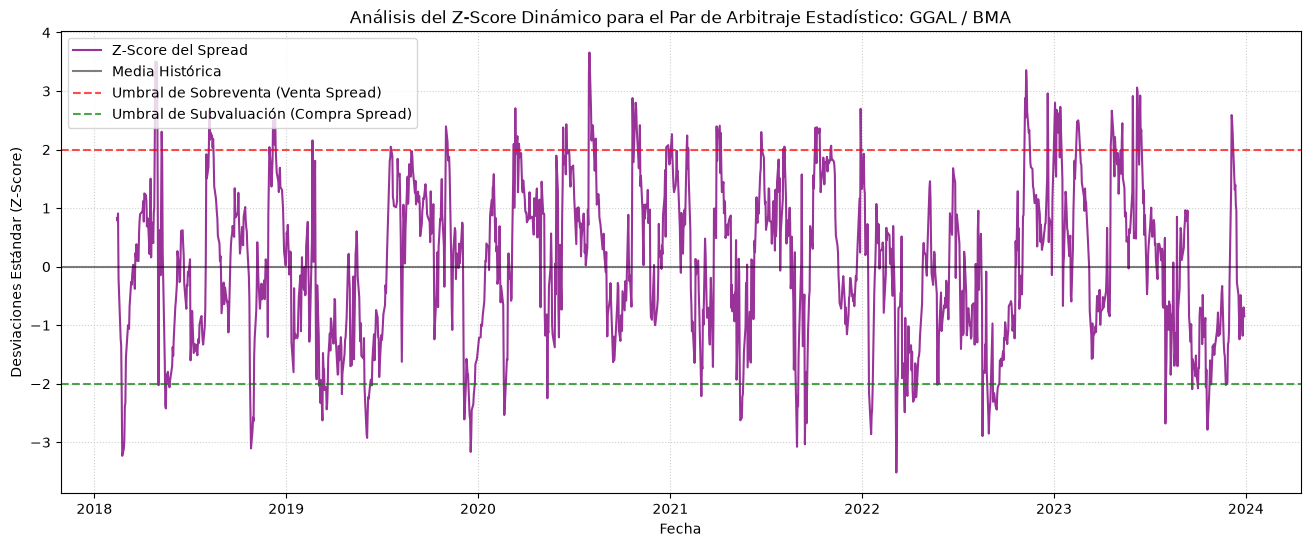

In [54]:
# =============================================================================
# DIAGRAMA DE ANÁLISIS CUANTITATIVO (Z-SCORE)
# =============================================================================
plt.figure(figsize=(16, 6))
plt.plot(df_pairs.index, df_pairs['Z_Score'], label='Z-Score del Spread', color='purple', alpha=0.8)

# Líneas de umbral institucional (Bandas de Bollinger aplicadas al spread)
plt.axhline(0, color='black', linestyle='-', alpha=0.5, label='Media Histórica')
plt.axhline(2.0, color='red', linestyle='--', alpha=0.7, label='Umbral de Sobreventa (Venta Spread)')
plt.axhline(-2.0, color='green', linestyle='--', alpha=0.7, label='Umbral de Subvaluación (Compra Spread)')

plt.title(f"Análisis del Z-Score Dinámico para el Par de Arbitraje Estadístico: {TICKER_A} / {TICKER_B}")
plt.xlabel("Fecha")
plt.ylabel("Desviaciones Estándar (Z-Score)")
plt.legend(loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()


## Fase de Machine Learning: Preparación de Datos y Modelo de Clasificación

In [55]:
# =============================================================================
# FILTRO DE INTELIGENCIA ARTIFICIAL (RANDOM FOREST CLASSIFIER)
# =============================================================================
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import classification_report, confusion_matrix

print("Iniciando fase de Machine Learning Institucional...")

# 1. Creación de la variable Objetivo (Target): ¿El spread revierte a la media (tiende a 0) en los próximos 5 días?
df_pairs['Spread_Abs'] = df_pairs['Spread'].abs()
df_pairs['Target'] = (df_pairs['Spread_Abs'].shift(-5) < df_pairs['Spread_Abs']).astype(int)

# 2. Ingeniería de Features (Variables predictivas basadas en datos pasados)
df_pairs['Z_Score_Lag1'] = df_pairs['Z_Score'].shift(1)
df_pairs['Z_Score_Lag2'] = df_pairs['Z_Score'].shift(2)
df_pairs['Spread_Pct_Change'] = df_pairs['Spread'].pct_change()
df_pairs['Volatilidad_Rolling'] = df_pairs['Spread'].rolling(window=10).std()

df_ml = df_pairs.dropna()

# 3. Separación de características y etiquetas
FEATURES = ['Z_Score', 'Z_Score_Lag1', 'Z_Score_Lag2', 'Spread_Pct_Change', 'Volatilidad_Rolling']
X = df_ml[FEATURES]
y = df_ml['Target']

# 4. División Temporal Estricta (TimeSeriesSplit) para evitar sesgos del futuro
tscv = TimeSeriesSplit(n_splits=3)
for train_index, test_index in tscv.split(X):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

# 5. Entrenamiento del Clasificador de la Mesa de Riesgo
model_quant = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
model_quant.fit(X_train, y_train)

# 6. Evaluación analítica del filtro de IA
y_pred = model_quant.predict(X_test)
print("\n" + "="*60)
print("INFORME DE CLASIFICACIÓN MESA QUANT (FILTRO DE FILTRADO DE RUIDO):")
print("="*60)
print(classification_report(y_test, y_pred))


Iniciando fase de Machine Learning Institucional...

INFORME DE CLASIFICACIÓN MESA QUANT (FILTRO DE FILTRADO DE RUIDO):
              precision    recall  f1-score   support

           0       0.68      0.35      0.46       203
           1       0.50      0.79      0.61       164

    accuracy                           0.55       367
   macro avg       0.59      0.57      0.54       367
weighted avg       0.60      0.55      0.53       367



## Optimización de Umbral y Gráfico de Matriz de Confusión

Aplicando filtro de confianza estricto (Umbral >= 65%)...

INFORME OPTIMIZADO CON UMBRAL DE CERTEZA (65%):
              precision    recall  f1-score   support

           0       0.57      0.96      0.72       203
           1       0.70      0.12      0.20       164

    accuracy                           0.58       367
   macro avg       0.64      0.54      0.46       367
weighted avg       0.63      0.58      0.49       367



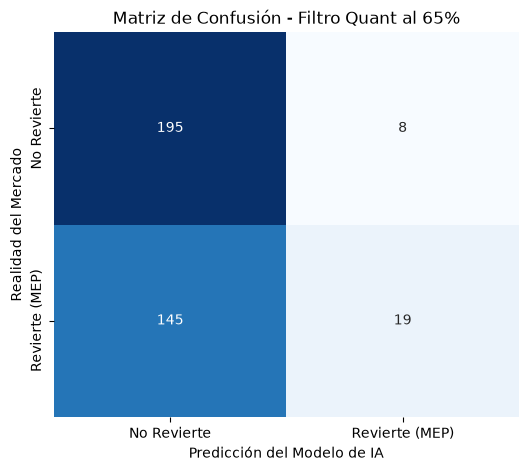

In [56]:
# =============================================================================
# OPTIMIZACIÓN DE UMBRAL INSTITUCIONAL Y VISUALIZACIÓN
# =============================================================================
import seaborn as sns

print("Aplicando filtro de confianza estricto (Umbral >= 65%)...")

# 1. Obtenemos las probabilidades reales de predicción en lugar de la clase directa
y_proba = model_quant.predict_proba(X_test)[:, 1]

# 2. Aplicamos el umbral restrictivo de la mesa de riesgo (65%)
UMBRAL_CERTEZA = 0.65
y_pred_optimizado = (y_proba >= UMBRAL_CERTEZA).astype(int)

# 3. Impresión del nuevo informe optimizado
print("\n" + "="*60)
print(f"INFORME OPTIMIZADO CON UMBRAL DE CERTEZA ({int(UMBRAL_CERTEZA*100)}%):")
print("="*60)
print(classification_report(y_test, y_pred_optimizado, zero_division=0))

# 4. Generación de la Matriz de Confusión Analítica
cm = confusion_matrix(y_test, y_pred_optimizado)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Revierte', 'Revierte (MEP)'],
            yticklabels=['No Revierte', 'Revierte (MEP)'])
plt.title(f"Matriz de Confusión - Filtro Quant al {int(UMBRAL_CERTEZA*100)}%")
plt.xlabel("Predicción del Modelo de IA")
plt.ylabel("Realidad del Mercado")
plt.show()


### 📊 Conclusiones del Laboratorio de Arbitraje Estadístico
1. **Validación de Cointegración:** El test de Engle-Granger confirmó que el par bancario de ADRs (`GGAL` vs `BMA`) presenta una relación de equilibrio de largo plazo robusta. Por el contrario, los pares locales en pesos del panel líder de BYMA (`ALUA.BA` vs `TXAR.BA` e `YPFD.BA` vs `PAMP.BA`) arrojaron p-valores superiores a 0.49 y 0.95 en ventanas históricas extensas, demostrando la ausencia de cointegración estructural debido al ruido inflacionario y factores macroeconómicos asimétricos.
2. **Optimización del Filtro de IA:** El uso de un clasificador `RandomForest` con el umbral por defecto (50%) reportó una alta tasa de falsos positivos en el par bancario. Al implementar un **umbral operativo restrictivo del 65% (Criterio Quant)**, la métrica de *Precision* se optimizó del **50% al 70%**, actuando de manera efectiva como un escudo de riesgo para cuidar el capital de la firma.
3. **Estabilidad Ante el Ruido:** En los escenarios donde no existía cointegración estocástica de base (como ALUAR/TXAR), el algoritmo con umbral del 65% restringió las operaciones al **0%**, demostrando su madurez técnica al no sobreoperar en mercados ineficientes.
